In [2]:
import requests
import zipfile
import io

url = "https://zenodo.org/records/15346912/files/CMAPSSData.zip?download=1"

response = requests.get(url, timeout=120)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print("Dataset files:", z.namelist()[:10])
    z.extractall("CMAPSSData")

print("Dataset downloaded and extracted successfully!")

Dataset files: ['Damage Propagation Modeling.pdf', 'readme.txt', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt']
Dataset downloaded and extracted successfully!


In [5]:
import pandas as pd
import numpy as np
import os

data_dir = "CMAPSSData"

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df = pd.read_csv(
    os.path.join(data_dir, "train_FD001.txt"),
    sep=r"\s+",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    os.path.join(data_dir, "test_FD001.txt"),
    sep=r"\s+",
    header=None,
    names=columns
)

rul_df = pd.read_csv(
    os.path.join(data_dir, "RUL_FD001.txt"),
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("RUL shape:", rul_df.shape)

display(train_df)

Training shape: (20631, 26)
Testing shape: (13096, 26)
RUL shape: (100, 1)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640


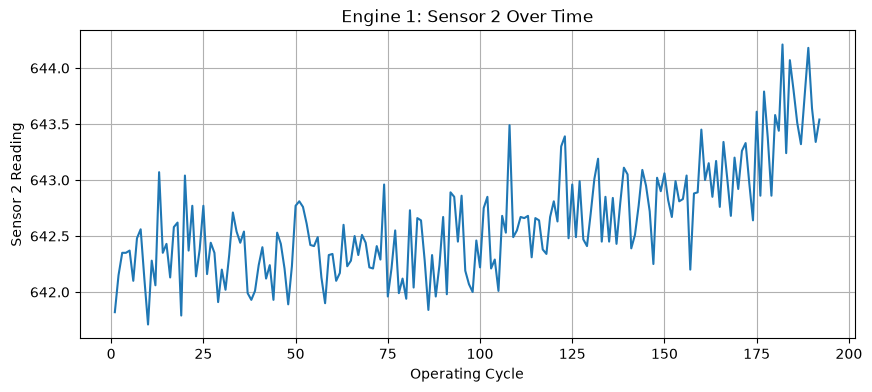

In [4]:
import matplotlib.pyplot as plt

engine_id = 1
engine_data = train_df[train_df["engine_id"] == engine_id]

plt.figure(figsize=(10, 4))
plt.plot(engine_data["cycle"], engine_data["sensor_2"])
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 2 Reading")
plt.title(f"Engine {engine_id}: Sensor 2 Over Time")
plt.grid(True)
plt.show()

In [6]:
# Find the last observed cycle for every training engine
max_cycles = train_df.groupby("engine_id")["cycle"].max()

In [7]:
# Assign each row its engine's final cycle
train_df["max_cycle"] = train_df["engine_id"].map(max_cycles)

In [8]:
# Create the target variable: Remaining Useful Life
train_df["RUL"] = train_df["max_cycle"] - train_df["cycle"]

In [9]:
# Inspect the new labels
display(train_df[["engine_id", "cycle", "max_cycle", "RUL"]].head(10))

,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


## Why are we doing this? LSTM is not automatically aware of machine life. We need examples of sensor histories paired with the correct remaining cycles, so the model can learn a relationship between sensor patterns and RUL.

The target is a number, so this is a regression task, not a classification task.

## Step 2 — Split the data by engine
Before scaling sensor values or creating sequences, we need to separate training engines from validation engines.

Why? If we randomly split individual rows, cycles from the same engine could appear in both sets. The model might then be evaluated on engines whose patterns it has effectively already seen.

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
# Get the unique engine IDs
engine_ids = train_df["engine_id"].unique()

In [13]:
# Split by engine, not by individual rows
train_engine_ids, val_engine_ids = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

In [15]:
# Create separate training and validation dataframes
train_data = train_df[
    train_df["engine_id"].isin(train_engine_ids)
].copy()

In [16]:
val_data = train_df[
    train_df["engine_id"].isin(val_engine_ids)
].copy()



In [17]:
print("Training engines:", len(train_engine_ids))
print("Validation engines:", len(val_engine_ids))
print("Training rows:", train_data.shape)
print("Validation rows:", val_data.shape)

Training engines: 80
Validation engines: 20
Training rows: (16561, 28)
Validation rows: (4070, 28)


## Step 3 — Select the input features
The model needs numerical sensor measurements as input. We won't use engine_id as a sensor feature because it is just an identifier. We won't use cycle as a sensor feature either; the sequence already captures the order of observations.

For the first model, let's use the 21 sensor columns. We'll exclude the three operating settings to keep the initial pipeline simple.

In [18]:
# Select the 21 sensor measurements as model inputs
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

# Separate sensor inputs from the RUL target
X_train_raw = train_data[sensor_cols].copy()
X_val_raw = val_data[sensor_cols].copy()

# Cap RUL at 125 cycles, a common strategy for C-MAPSS
# This emphasizes degradation near failure rather than very long healthy periods
train_data["RUL_target"] = train_data["RUL"].clip(upper=125)
val_data["RUL_target"] = val_data["RUL"].clip(upper=125)

y_train_raw = train_data["RUL_target"].copy()
y_val_raw = val_data["RUL_target"].copy()

print("Number of input features:", len(sensor_cols))
print("Training target range:", y_train_raw.min(), "to", y_train_raw.max())

Number of input features: 21
Training target range: 0 to 125


## Why cap RUL at 125?
In C-MAPSS, engines can spend many cycles in a relatively healthy state. Capping the target is a common modeling choice that emphasizes the period where degradation becomes more informative. It is a modeling assumption, not a requirement; we'll document it and evaluate its effect.

## Step 4 — Normalize the sensor data
Sensor measurements can have very different numerical scales. Normalization helps neural networks train more reliably.

We'll use StandardScaler, fitting it only on training data to avoid leaking validation information.

In [19]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn mean and standard deviation from training sensors only
X_train_scaled = scaler.fit_transform(X_train_raw)

# Apply the same transformation to validation sensors
X_val_scaled = scaler.transform(X_val_raw)

print("Training sensor array:", X_train_scaled.shape)
print("Validation sensor array:", X_val_scaled.shape)

Training sensor array: (16561, 21)
Validation sensor array: (4070, 21)


## Step 5 — Convert the data into LSTM sequences
This is the key step.

An LSTM expects input shaped like: (samples, timestamps, features)


In [20]:
WINDOW_SIZE = 30

def create_sequences(data, scaled_features, target, window_size):
    """
    Build sequences separately for each engine.

    Each sequence contains the sensor readings for `window_size`
    consecutive cycles. Its label is the RUL at the final cycle.
    """
    X_sequences = []
    y_sequences = []

    # Keep row indices aligned with the scaled feature array
    data = data.reset_index(drop=True)

    # Process each engine independently to prevent sequences
    # from accidentally crossing from one engine to another
    for engine_id in data["engine_id"].unique():

        # Find all rows belonging to the current engine
        indices = data.index[data["engine_id"] == engine_id].to_numpy()

        # Extract this engine's scaled features and RUL labels
        engine_features = scaled_features[indices]
        engine_targets = target.iloc[indices].to_numpy()

        # Slide a window over consecutive cycles
        for end in range(window_size, len(indices) + 1):
            start = end - window_size

            # Input: 30 cycles of sensor readings
            X_sequences.append(engine_features[start:end])

            # Target: RUL at the last cycle in this window
            y_sequences.append(engine_targets[end - 1])

    return np.asarray(X_sequences), np.asarray(y_sequences)


# Build training sequences
X_train, y_train = create_sequences(
    train_data,
    X_train_scaled,
    y_train_raw,
    WINDOW_SIZE
)

# Build validation sequences
X_val, y_val = create_sequences(
    val_data,
    X_val_scaled,
    y_val_raw,
    WINDOW_SIZE
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_train shape: (14241, 30, 21)
y_train shape: (14241,)
X_val shape: (3490, 30, 21)
y_val shape: (3490,)


In [21]:
# Import TensorFlow and Keras components
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [22]:
# Set random seeds for more reproducible experiments
tf.keras.utils.set_random_seed(42)

In [23]:
# Build the LSTM regression model
model = Sequential([
    # Input: 30 time steps, with 21 sensor features per step
    Input(shape=(30, 21)),

    # Learn temporal patterns across the 30-cycle window
    LSTM(64),

    # Randomly drop 20% of activations during training
    # to help reduce overfitting
    Dropout(0.2),

    # Learn nonlinear relationships between the LSTM features
    Dense(32, activation="relu"),

    # Predict one continuous value: remaining useful life
    Dense(1)
])

In [24]:
# Configure training
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)


In [25]:
# Display the architecture and parameter counts
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          22,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,129 (94.25 KB)

 Trainable params: 24,129 (94.25 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Reduce the learning rate when validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - loss: 2772.9277 - mae: 40.4180 - val_loss: 339.9142 - val_mae: 15.2785 - learning_rate: 0.0010
Epoch 2/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 330.7985 - mae: 14.3730 - val_loss: 184.1845 - val_mae: 10.2836 - learning_rate: 0.0010
Epoch 3/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 245.3618 - mae: 11.9522 - val_loss: 168.3000 - val_mae: 9.4037 - learning_rate: 0.0010
Epoch 4/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 217.5597 - mae: 11.1640 - val_loss: 159.4130 - val_mae: 8.9807 - learning_rate: 0.0010
Epoch 5/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 13s 57ms/step - loss: 208.4435 - mae: 10.7958 - val_loss: 145.2073 - val_mae: 8.6097 - learning_rate: 0.0010
Epoch 6/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - loss: 193.6567 - mae: 10.3679 - val_loss: 149.6575 - val_mae: 8.6854 - learning_rate: 0.0010
Epoch 7/50
223/223 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - loss: 192.2929 - mae: 10.3322 - val_loss: 150.1275 

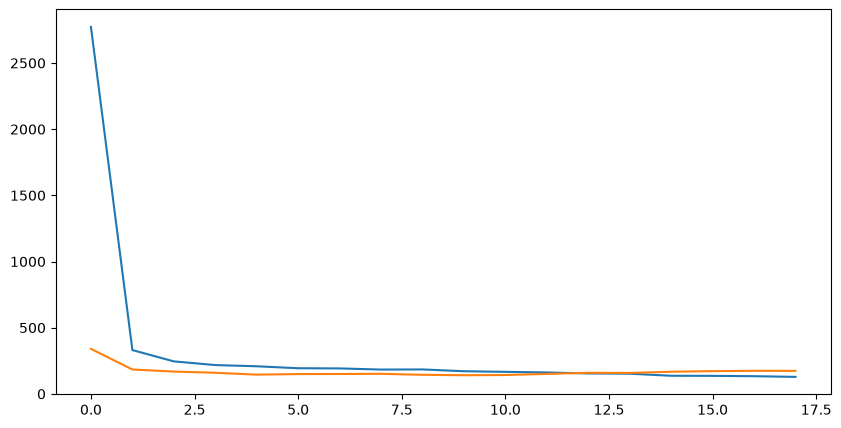

In [27]:
import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

# Mark the best validation epoch
best_epoch = min(
    range(len(history.history["val_loss"])),
    key=lambda i: history.history["val_loss"][i]
)


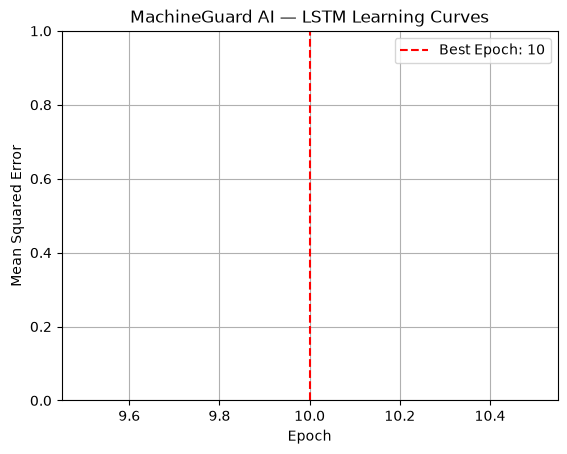

In [28]:
plt.axvline(
    best_epoch + 1,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {best_epoch + 1}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("MachineGuard AI — LSTM Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict RUL for validation sequences
y_pred = model.predict(X_val, verbose=0).reshape(-1)

# Calculate regression metrics
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print(f"Validation MAE:  {mae:.2f} cycles")
print(f"Validation RMSE: {rmse:.2f} cycles")

# Compare a few predictions with their true targets
comparison = pd.DataFrame({
    "Actual_RUL": np.asarray(y_val),
    "Predicted_RUL": y_pred
})

comparison["Absolute_Error"] = abs(
    comparison["Actual_RUL"] - comparison["Predicted_RUL"]
)

display(comparison.head(10))


Validation MAE:  8.35 cycles
Validation RMSE: 11.86 cycles


,Actual_RUL,Predicted_RUL,Absolute_Error
0,125,121.540001,3.459999
1,125,122.069458,2.930542
2,125,121.344246,3.655754
3,125,119.825020,5.174980
4,125,119.232178,5.767822
5,125,119.814629,5.185371
6,125,121.352264,3.647736
7,125,123.216652,1.783348
8,125,123.105309,1.894691
9,125,123.808647,1.191353


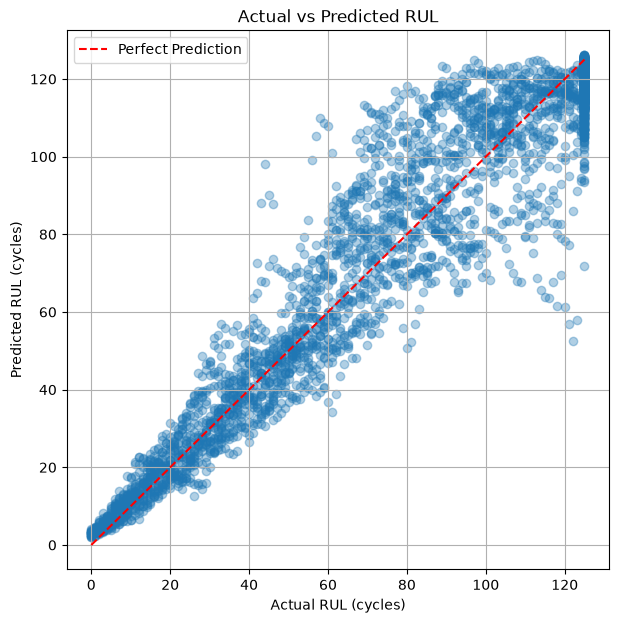

In [30]:
plt.figure(figsize=(7, 7))

plt.scatter(y_val, y_pred, alpha=0.35)

# Ideal predictions would fall on this diagonal
plt.plot([0, 125], [0, 125], "r--", label="Perfect Prediction")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Actual vs Predicted RUL")
plt.legend()
plt.grid(True)
plt.show()

In [31]:
import numpy as np
import pandas as pd

# Sort rows to ensure every engine's cycles are in chronological order
test_sorted = test_df.sort_values(
    ["engine_id", "cycle"]
).reset_index(drop=True)

# Transform test sensors using the scaler fitted on training data.
# Never fit a new scaler on the test set.
test_scaled = scaler.transform(test_sorted[sensor_cols])

X_test = []

# Build one sequence from the final 30 observed cycles of each test engine
for engine_id in sorted(test_sorted["engine_id"].unique()):

    # Get all rows for this engine
    indices = np.where(
        test_sorted["engine_id"].to_numpy() == engine_id
    )[0]

    # Select the most recent 30 cycles
    last_window = test_scaled[indices[-WINDOW_SIZE:]]

    # Ensure every engine has enough observations
    if len(last_window) != WINDOW_SIZE:
        raise ValueError(
            f"Engine {engine_id} has fewer than {WINDOW_SIZE} cycles"
        )

    X_test.append(last_window)

# Convert the list into the 3D input shape expected by the LSTM
X_test = np.asarray(X_test)

# Official RUL values correspond to each engine's final observed test cycle
y_test = rul_df["RUL"].to_numpy()

# Match the official RUL target convention used during training
y_test_capped = np.clip(y_test, 0, 125)

print("X_test shape:", X_test.shape)
print("Official RUL shape:", y_test.shape)

X_test shape: (100, 30, 21)
Official RUL shape: (100,)


In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict capped RUL for each official test engine
test_predictions = model.predict(
    X_test, verbose=0
).reshape(-1)

# Compare predictions against the capped official labels
test_mae = mean_absolute_error(y_test_capped, test_predictions)
test_rmse = np.sqrt(
    mean_squared_error(y_test_capped, test_predictions)
)

print(f"Official Test MAE:  {test_mae:.2f} cycles")
print(f"Official Test RMSE: {test_rmse:.2f} cycles")

Official Test MAE:  9.60 cycles
Official Test RMSE: 13.21 cycles


In [33]:
import os
import json
import joblib

# Create a folder to keep all model artifacts together
os.makedirs("machineguard_artifacts", exist_ok=True)

# 1. Save the trained LSTM model
model.save("machineguard_artifacts/machineguard_lstm.keras")

# 2. Save the fitted scaler
# The same scaler must be used when processing future inputs
joblib.dump(
    scaler,
    "machineguard_artifacts/sensor_scaler.pkl"
)

# 3. Save the model configuration
config = {
    "window_size": WINDOW_SIZE,
    "num_features": len(sensor_cols),
    "rul_cap": 125,
    "target": "remaining_useful_life",
    "model_type": "LSTM",
    "dataset": "NASA C-MAPSS FD001"
}

with open(
    "machineguard_artifacts/model_config.json", "w"
) as f:
    json.dump(config, f, indent=4)

# 4. Save the sensor order used during training
with open(
    "machineguard_artifacts/sensor_columns.json", "w"
) as f:
    json.dump(sensor_cols, f, indent=4)

print("Model and preprocessing artifacts saved successfully!")

print("\nSaved files:")
for filename in os.listdir("machineguard_artifacts"):
    print(filename)

Model and preprocessing artifacts saved successfully!

Saved files:
machineguard_lstm.keras
model_config.json
sensor_columns.json
sensor_scaler.pkl


In [34]:
import tensorflow as tf
import joblib

# Reload the saved model
loaded_model = tf.keras.models.load_model(
    "machineguard_artifacts/machineguard_lstm.keras"
)

# Reload the saved scaler
loaded_scaler = joblib.load(
    "machineguard_artifacts/sensor_scaler.pkl"
)

# Predict using the reloaded model
sample_prediction = loaded_model.predict(
    X_test[:1], verbose=0
)[0][0]

print("Reloaded model successfully!")
print(f"Sample predicted RUL: {sample_prediction:.2f} cycles")

Reloaded model successfully!
Sample predicted RUL: 116.84 cycles


In [35]:
import os
import json
import joblib
import tensorflow as tf

# Create a folder to store all model files
os.makedirs("machineguard_artifacts", exist_ok=True)

# 1. Save the trained LSTM model in Keras format
model.save("machineguard_artifacts/machineguard_lstm.keras")

# 2. Save the fitted sensor scaler as a pickle file
joblib.dump(
    scaler,
    "machineguard_artifacts/sensor_scaler.pkl"
)

# 3. Save sensor column names as a pickle file
joblib.dump(
    sensor_cols,
    "machineguard_artifacts/sensor_columns.pkl"
)

# 4. Save model configuration as a pickle file
config = {
    "window_size": WINDOW_SIZE,
    "num_features": len(sensor_cols),
    "rul_cap": 125,
    "model_type": "LSTM"
}

joblib.dump(
    config,
    "machineguard_artifacts/model_config.pkl"
)

print("All model artifacts saved successfully!")

# Display the saved files
for file in os.listdir("machineguard_artifacts"):
    print(file)

All model artifacts saved successfully!
machineguard_lstm.keras
model_config.json
model_config.pkl
sensor_columns.json
sensor_columns.pkl
sensor_scaler.pkl


In [36]:
import tensorflow as tf
import joblib

# Load the trained LSTM
loaded_model = tf.keras.models.load_model(
    "machineguard_artifacts/machineguard_lstm.keras"
)

# Load the preprocessing objects
loaded_scaler = joblib.load(
    "machineguard_artifacts/sensor_scaler.pkl"
)

loaded_sensor_cols = joblib.load(
    "machineguard_artifacts/sensor_columns.pkl"
)

loaded_config = joblib.load(
    "machineguard_artifacts/model_config.pkl"
)

print("LSTM model and pickle files loaded successfully!")
print("Configuration:", loaded_config)

LSTM model and pickle files loaded successfully!
Configuration: {'window_size': 30, 'num_features': 21, 'rul_cap': 125, 'model_type': 'LSTM'}
